# Лабораторная работа № 1. Прикладная задача на табличных данных

**Вариант 2 — кредитный скоринг** (Home Credit Default Risk, `application_train.csv`).
Номер в списке группы — 2, 2 mod 8 = 2.

Решение — одобрить или отклонить заявку на кредит. Цена ошибок: выдача кредита неплательщику
C_FN = 100 000 ₽, отказ надёжному клиенту C_FP = 15 000 ₽ упущенного дохода.
Валидация — стратифицированная 5-fold, отложенная выборка 20 %.

Ноутбук выполняется сверху вниз после перезапуска ядра. Функции признаков — в модуле `features.py`.

## Шаг 0. Окружение и константы

In [1]:
import os, sys, json, time, subprocess, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, lightgbm as lgb, catboost, optuna, shap

from sklearn.model_selection import (StratifiedKFold, train_test_split,
                                     cross_val_score, cross_val_predict)
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix)
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from catboost import CatBoostClassifier

import features as F

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
C_FN, C_FP = 100_000.0, 15_000.0           # выдача неплательщику / отказ надёжному
T_THEORY = C_FP / (C_FP + C_FN)
FAST = os.environ.get('LAB_FAST') == '1'   # быстрый прогон для отладки (подвыборка)
N_TRIALS = 5 if FAST else 50
DATA = 'data/application_train.csv'
EXP_LOG = 'experiments.csv'
R = {}                                     # итоговые числа для отчёта

os.makedirs('figures', exist_ok=True)
if os.path.exists(EXP_LOG):
    os.remove(EXP_LOG)                     # журнал пишется заново при полном прогоне
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'font.size': 11})
print(sys.version.split()[0], 'sklearn', sklearn.__version__, 'lightgbm', lgb.__version__,
      'catboost', catboost.__version__, 'optuna', optuna.__version__, 'shap', shap.__version__)
print('t* =', round(T_THEORY, 4))

/private/tmp/claude-501/-Users-st1ck-Documents-ChatGPT-VPN/5449043f-518d-41c9-9e7a-55893a834eff/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


3.11.0 sklearn 1.9.1 lightgbm 4.7.0 catboost 1.2.10 optuna 5.0.0 shap 0.51.0
t* = 0.1304


## Шаг 1. Загрузка данных и постановка

In [2]:
if not os.path.exists(DATA):
    # нужен токен Kaggle и принятые правила соревнования home-credit-default-risk
    import kagglehub, shutil
    path = kagglehub.competition_download('home-credit-default-risk')
    os.makedirs('data', exist_ok=True)
    shutil.copy(os.path.join(path, 'application_train.csv'), DATA)

df = pd.read_csv(DATA)
if FAST:
    df = df.sample(30_000, random_state=RANDOM_STATE)
print(df.shape)
print(df['TARGET'].value_counts().rename({0: 'вернул', 1: 'дефолт'}))
R['n_rows'], R['n_cols'] = df.shape
R['default_rate'] = df['TARGET'].mean()

(307511, 122)
TARGET
вернул    282686
дефолт     24825
Name: count, dtype: int64


**Постановка задачи.**

| Элемент | Значение |
|---|---|
| Решение и исполнитель | Кредитный отдел (автоматический скоринг + андеррайтер) одобряет или отклоняет заявку |
| Момент прогноза | Подача заявки, до выдачи кредита |
| Объект | Одна заявка (строка `application_train.csv`, `SK_ID_CURR` уникален) |
| Целевая переменная | `TARGET` = 1 — у клиента была просрочка платежа (дефолт) в начальный период кредита |
| Признаки | Анкета, суммы кредита и аннуитета, занятость, жильё, внешние скоринги `EXT_SOURCE_*`, запросы в бюро |
| Метрика | ROC-AUC (основная), PR-AUC (дополнительная), бизнес-метрика — суммарная стоимость ошибок |
| Цена ошибок | FN (выдали неплательщику) = 100 000 ₽, FP (отказали надёжному) = 15 000 ₽ |
| Ограничения | Ответ за секунды, объяснимость отказа клиенту и регулятору, недопустимость дискриминации |

## Шаг 2. Разведочный анализ

In [3]:
dtypes = df.dtypes.astype(str).value_counts()
print(dtypes)
miss = df.isna().mean().sort_values(ascending=False)
print('Столбцов с пропусками:', (miss > 0).sum(), '; более 50 %:', (miss > 0.5).sum())
print(miss.head(8).round(3))
dup_full = df.drop(columns='SK_ID_CURR').duplicated().sum()
print('Полных дубликатов (без ID):', dup_full, '; ID уникален:', df['SK_ID_CURR'].is_unique)

housing = [c for c in df.columns if c.endswith(('_AVG', '_MODE', '_MEDI'))]
R.update(miss_cols=int((miss > 0).sum()), miss_cols_50=int((miss > 0.5).sum()),
         dup_full=int(dup_full), n_housing=len(housing),
         housing_miss_mean=float(df[housing].isna().mean().mean()),
         top_missing={k: float(v) for k, v in miss.head(5).items()},
         n_numeric=int((df.dtypes != object).sum()) - 2, n_object=int((df.dtypes == object).sum()))
print('Признаков о жилье:', len(housing), '; средняя доля пропусков:', round(R['housing_miss_mean'], 3))

float64    65
int64      41
str        16
Name: count, dtype: int64
Столбцов с пропусками: 67 ; более 50 %: 41
COMMONAREA_MEDI             0.699
COMMONAREA_AVG              0.699
COMMONAREA_MODE             0.699
NONLIVINGAPARTMENTS_MODE    0.694
NONLIVINGAPARTMENTS_AVG     0.694
NONLIVINGAPARTMENTS_MEDI    0.694
FONDKAPREMONT_MODE          0.684
LIVINGAPARTMENTS_MODE       0.684
dtype: float64


Полных дубликатов (без ID): 0 ; ID уникален: True
Признаков о жилье: 47 ; средняя доля пропусков: 0.579


In [4]:
# ловушка варианта: DAYS_EMPLOYED = 365243 — служебный код
anom = df['DAYS_EMPLOYED'] == F.DAYS_EMPLOYED_CODE
print('DAYS_EMPLOYED = 365243:', anom.sum(), f'({anom.mean():.1%})')
print('Доля дефолтов: код =', round(df.loc[anom, 'TARGET'].mean(), 4),
      '; остальные =', round(df.loc[~anom, 'TARGET'].mean(), 4))
print(df.loc[anom, 'NAME_INCOME_TYPE'].value_counts().head(3))
print('CODE_GENDER:', df['CODE_GENDER'].value_counts().to_dict())
R.update(anom_n=int(anom.sum()), anom_share=float(anom.mean()),
         anom_rate=float(df.loc[anom, 'TARGET'].mean()),
         nonanom_rate=float(df.loc[~anom, 'TARGET'].mean()),
         anom_pensioner=float((df.loc[anom, 'NAME_INCOME_TYPE'] == 'Pensioner').mean()),
         gender_counts=df['CODE_GENDER'].value_counts().to_dict())

DAYS_EMPLOYED = 365243: 55374 (18.0%)
Доля дефолтов: код = 0.054 ; остальные = 0.0866
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64
CODE_GENDER: {'F': 202448, 'M': 105059, 'XNA': 4}


In [5]:
# редкие категории (< 1 %) и доля дефолтов по категориям
rare = {}
for c in F.CAT_COLS:
    freq = df[c].value_counts(normalize=True)
    rare[c] = int((freq < 0.01).sum())
print('Редких категорий по столбцам:', {k: v for k, v in rare.items() if v})
R['rare_total'] = int(sum(rare.values()))
for c in ['NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'NAME_CONTRACT_TYPE']:
    print(df.groupby(c)['TARGET'].agg(['size', 'mean']).sort_values('mean').round(3), '\n')
R['edu_rates'] = df.groupby('NAME_EDUCATION_TYPE')['TARGET'].mean().round(4).to_dict()

Редких категорий по столбцам: {'CODE_GENDER': 1, 'NAME_TYPE_SUITE': 3, 'NAME_INCOME_TYPE': 4, 'NAME_EDUCATION_TYPE': 1, 'NAME_FAMILY_STATUS': 1, 'NAME_HOUSING_TYPE': 2, 'OCCUPATION_TYPE': 6, 'ORGANIZATION_TYPE': 41, 'HOUSETYPE_MODE': 2}
                                 size   mean
NAME_EDUCATION_TYPE                         
Academic degree                   164  0.018
Higher education                74863  0.054
Incomplete higher               10277  0.085
Secondary / secondary special  218391  0.089
Lower secondary                  3816  0.109 

                        size   mean
NAME_INCOME_TYPE                   
Businessman               10  0.000
Student                   18  0.000
Pensioner              55362  0.054
State servant          21703  0.058
Commercial associate   71617  0.075
Working               158774  0.096
Unemployed                22  0.364
Maternity leave            5  0.400 

                      size   mean
NAME_CONTRACT_TYPE               
Revolving loans 

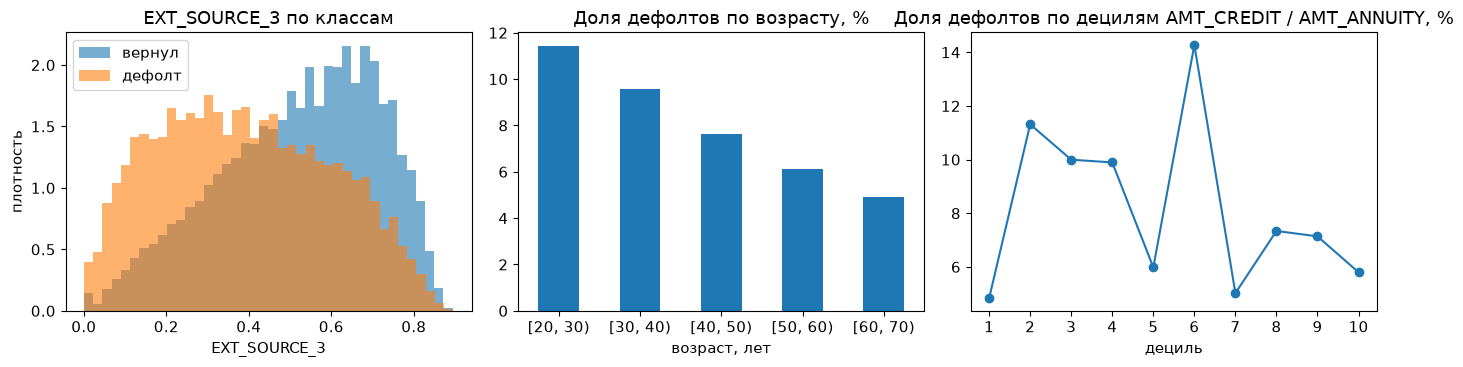

In [6]:
age = -df['DAYS_BIRTH'] / 365.25
age_bin = pd.cut(age, [20, 30, 40, 50, 60, 70], right=False)
R['age_rates'] = {str(k): float(v) for k, v in df.groupby(age_bin)['TARGET'].mean().items()}
R['ext3_median'] = df.groupby('TARGET')['EXT_SOURCE_3'].median().round(3).to_dict()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for t, lab in [(0, 'вернул'), (1, 'дефолт')]:
    ax[0].hist(df.loc[df['TARGET'] == t, 'EXT_SOURCE_3'].dropna(), bins=40,
               density=True, alpha=0.6, label=lab)
ax[0].set(title='EXT_SOURCE_3 по классам', xlabel='EXT_SOURCE_3', ylabel='плотность')
ax[0].legend()
df.groupby(age_bin)['TARGET'].mean().mul(100).plot.bar(ax=ax[1], color='tab:blue')
ax[1].set(title='Доля дефолтов по возрасту, %', xlabel='возраст, лет')
ax[1].tick_params(axis='x', rotation=0)
cr = df['AMT_CREDIT'] / df['AMT_ANNUITY']
df.groupby(pd.qcut(cr, 10, duplicates='drop'))['TARGET'].mean().mul(100).plot(
    ax=ax[2], marker='o')
ax[2].set(title='Доля дефолтов по децилям AMT_CREDIT / AMT_ANNUITY, %', xlabel='дециль')
ax[2].set_xticks(range(10)); ax[2].set_xticklabels(range(1, 11))
plt.tight_layout(); plt.savefig('figures/eda.png'); plt.show()

### Поиск утечек

In [7]:
def leak_scan(df, target):
    # ROC-AUC каждого признака по отдельности; target — столбец 0/1
    scores = {}
    for col in df.columns.drop(target):
        x = df[col]
        if not pd.api.types.is_numeric_dtype(x):
            # грубое кодирование средним таргета — только для поиска утечек
            x = x.map(df.groupby(col)[target].mean())
        x = pd.to_numeric(x, errors='coerce').astype(float)
        x = x.fillna(x.median())
        if x.nunique() < 2:
            continue
        auc = roc_auc_score(df[target], x)
        scores[col] = max(auc, 1 - auc)
    return pd.Series(scores).sort_values(ascending=False)

leaks = leak_scan(df, 'TARGET')
print(leaks.head(10).round(4))
print('Признаков с ROC-AUC > 0,9:', (leaks > 0.9).sum())
R['leak_top'] = {k: float(v) for k, v in leaks.head(10).items()}
R['leak_id'] = float(leaks.get('SK_ID_CURR', np.nan))

EXT_SOURCE_2                   0.6559
EXT_SOURCE_3                   0.6493
DAYS_BIRTH                     0.5830
EXT_SOURCE_1                   0.5820
ORGANIZATION_TYPE              0.5743
OCCUPATION_TYPE                0.5672
NAME_INCOME_TYPE               0.5612
DAYS_LAST_PHONE_CHANGE         0.5569
DAYS_ID_PUBLISH                0.5557
REGION_RATING_CLIENT_W_CITY    0.5492
dtype: float64
Признаков с ROC-AUC > 0,9: 0


Ни один признак не превышает ROC-AUC 0,9, явных утечек нет: все столбцы `application_train`
заполнены на момент подачи заявки. Исключается идентификатор `SK_ID_CURR`. Исправляются ловушки:
`DAYS_EMPLOYED = 365243` → пропуск + флаг `DAYS_EMPLOYED_ANOM`; `CODE_GENDER = XNA` → пропуск;
числовые признаки о жилье `_MODE` и `_MEDI` дублируют `_AVG` и удаляются (проверено ниже).

## Шаг 3. Разбиение и baseline

In [8]:
X, y = df.drop(columns='TARGET'), df['TARGET']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
print('train', X_train.shape, round(y_train.mean(), 4), '| test', X_test.shape, round(y_test.mean(), 4))
R.update(n_train=len(X_train), n_test=len(X_test), train_rate=float(y_train.mean()),
         test_rate=float(y_test.mean()), test_pos=int(y_test.sum()))

def log_experiment(model, features, params, scores, path=EXP_LOG, note=''):
    row = {'time': dt.datetime.now().isoformat(timespec='seconds'), 'model': model,
           'features': features, 'params': json.dumps(params, ensure_ascii=False, default=str),
           'cv_mean': float(np.mean(scores)), 'cv_std': float(np.std(scores)),
           'n_folds': len(scores), 'note': note}
    pd.DataFrame([row]).to_csv(path, mode='a', index=False, header=not os.path.exists(path))

train (246008, 121) 0.0807 | test (61503, 121) 0.0807


In [9]:
preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
     make_column_selector(dtype_include='number')),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='infrequent_if_exist',
                                        min_frequency=0.01)),
     make_column_selector(dtype_exclude='number')),
])
baselines = {
    'dummy': DummyClassifier(strategy='prior'),
    'logreg': make_pipeline(FunctionTransformer(F.clean), preprocess,
                            LogisticRegression(max_iter=2000)),
}
R['cv'] = {}
for name, model in baselines.items():
    t0 = time.time()
    s = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    log_experiment(name, 'clean', {}, s, note='baseline')
    R['cv'][name] = (float(s.mean()), float(s.std()))
    print(f'{name}: {s.mean():.4f} ± {s.std():.4f}  ({time.time() - t0:.0f} с)')

dummy: 0.5000 ± 0.0000  (1 с)


logreg: 0.7452 ± 0.0030  (28 с)


## Шаг 4. Признаки и пайплайн (абляция)

In [10]:
LGB_QUICK = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=0.8,
                 subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE,
                 verbose=-1)

def cv_lgb(Xf, params=LGB_QUICK, cv=cv3):
    return cross_val_score(lgb.LGBMClassifier(**params), Xf, y_train, cv=cv, scoring='roc_auc')

Xtr_base = F.to_category(F.clean(X_train))             # без новых признаков
Xtr_fe = F.prepare(X_train)                            # + 10 новых признаков
dups = F.housing_duplicates(X_train.columns)
Xtr_dups = Xtr_base.join(X_train[dups])                # с дублями _MODE/_MEDI

s_dups, s_base, s_full = cv_lgb(Xtr_dups), cv_lgb(Xtr_base), cv_lgb(Xtr_fe)
for nm, s in [('с дублями о жилье', s_dups), ('без дублей (base)', s_base), ('base + 10 новых', s_full)]:
    print(f'{nm}: {s.mean():.4f} ± {s.std():.4f}')
log_experiment('lightgbm', 'clean+housing_dups', LGB_QUICK, s_dups, note='ablation')
log_experiment('lightgbm', 'clean', LGB_QUICK, s_base, note='ablation')
log_experiment('lightgbm', 'clean+fe10', LGB_QUICK, s_full, note='ablation')
R['abl_dups'] = (float(s_dups.mean()), float(s_dups.std()))
R['abl_base'] = (float(s_base.mean()), float(s_base.std()))
R['abl_full'] = (float(s_full.mean()), float(s_full.std()))
R['n_dups'] = len(dups); R['n_feat_base'] = Xtr_base.shape[1]; R['n_feat_fe'] = Xtr_fe.shape[1]

с дублями о жилье: 0.7530 ± 0.0021
без дублей (base): 0.7537 ± 0.0008
base + 10 новых: 0.7617 ± 0.0006


In [11]:
abl = []
for f in F.NEW_FEATURES:
    s = cv_lgb(Xtr_fe.drop(columns=f))
    log_experiment('lightgbm', f'fe10-{f}', LGB_QUICK, s, note='ablation')
    abl.append({'feature': f, 'auc_without': s.mean(), 'contribution': s_full.mean() - s.mean()})
abl = pd.DataFrame(abl).sort_values('contribution', ascending=False)
abl['decision'] = np.where(abl['contribution'] > 0, 'оставить', 'удалить')
REMOVED = abl.loc[abl['decision'] == 'удалить', 'feature'].tolist()
print(abl.round(5).to_string(index=False))
print('Удаляются:', REMOVED)
R['ablation'] = abl.to_dict('records'); R['removed'] = REMOVED

             feature  auc_without  contribution decision
         CREDIT_TERM      0.75578       0.00591 оставить
           AGE_YEARS      0.75928       0.00241 оставить
          DOCS_COUNT      0.76082       0.00086 оставить
 CREDIT_INCOME_RATIO      0.76093       0.00076 оставить
     EXT_SOURCE_MEAN      0.76109       0.00060 оставить
  GOODS_CREDIT_RATIO      0.76109       0.00059 оставить
ANNUITY_INCOME_RATIO      0.76153       0.00015 оставить
   INCOME_PER_PERSON      0.76176      -0.00008  удалить
     EMPLOYED_TO_AGE      0.76188      -0.00020  удалить
      EXT_SOURCE_STD      0.76195      -0.00027  удалить
Удаляются: ['INCOME_PER_PERSON', 'EMPLOYED_TO_AGE', 'EXT_SOURCE_STD']


In [12]:
fe = make_pipeline(FunctionTransformer(F.prepare),
                   FunctionTransformer(F.drop_columns, kw_args={'cols': REMOVED}))
X_train_fe = fe.fit_transform(X_train)
X_test_fe = fe.transform(X_test)
s_sel = cv_lgb(X_train_fe)
log_experiment('lightgbm', 'final_features', LGB_QUICK, s_sel, note='ablation')
cat_cols = [c for c in F.CAT_COLS if c in X_train_fe.columns]
print(X_train_fe.shape, f'{s_sel.mean():.4f} ± {s_sel.std():.4f}')
R['abl_sel'] = (float(s_sel.mean()), float(s_sel.std())); R['n_feat_final'] = X_train_fe.shape[1]

(246008, 99) 0.7612 ± 0.0008


## Шаг 5. Модели и подбор гиперпараметров

In [13]:
# LightGBM по умолчанию — 5 фолдов на всей обучающей выборке
LGB_DEFAULT = dict(random_state=RANDOM_STATE, verbose=-1)
t0 = time.time()
s = cross_val_score(lgb.LGBMClassifier(**LGB_DEFAULT), X_train_fe, y_train, cv=cv, scoring='roc_auc')
log_experiment('lightgbm', 'final_features', LGB_DEFAULT, s, note='default')
R['cv']['lgb_default'] = (float(s.mean()), float(s.std()))
print(f'LightGBM default: {s.mean():.4f} ± {s.std():.4f} ({time.time() - t0:.0f} с)')

LightGBM default: 0.7616 ± 0.0011 (13 с)


In [14]:
# Optuna: набор > 100 тыс. строк, поэтому подвыборка 100 тыс. и 3 фолда
if len(X_train_fe) > 100_000:
    X_sub, _, y_sub, _ = train_test_split(X_train_fe, y_train, train_size=100_000,
                                          stratify=y_train, random_state=RANDOM_STATE)
else:
    X_sub, y_sub = X_train_fe, y_train

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 1500, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 8, 128, log=True),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 500, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.2, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 30.0, log=True),
        'subsample_freq': 1, 'random_state': RANDOM_STATE, 'verbose': -1,
    }
    s = cross_val_score(lgb.LGBMClassifier(**params), X_sub, y_sub, cv=cv3, scoring='roc_auc')
    log_experiment('lightgbm', 'final_features', params, s, note=f'optuna #{trial.number}')
    return s.mean()

t0 = time.time()
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=N_TRIALS)
best_params = {**study.best_params, 'subsample_freq': 1, 'random_state': RANDOM_STATE, 'verbose': -1}
R['optuna'] = dict(n_trials=len(study.trials), best=float(study.best_value),
                   minutes=(time.time() - t0) / 60, n_sub=len(X_sub), params=study.best_params)
print(f'{len(study.trials)} испытаний, {R["optuna"]["minutes"]:.1f} мин, лучший ROC-AUC {study.best_value:.4f}')
print(study.best_params)

50 испытаний, 34.8 мин, лучший ROC-AUC 0.7623
{'n_estimators': 1400, 'learning_rate': 0.01221912757721042, 'num_leaves': 17, 'min_child_samples': 38, 'subsample': 0.9244701062631703, 'colsample_bytree': 0.21421035494625656, 'reg_lambda': 1.2527633520783394}


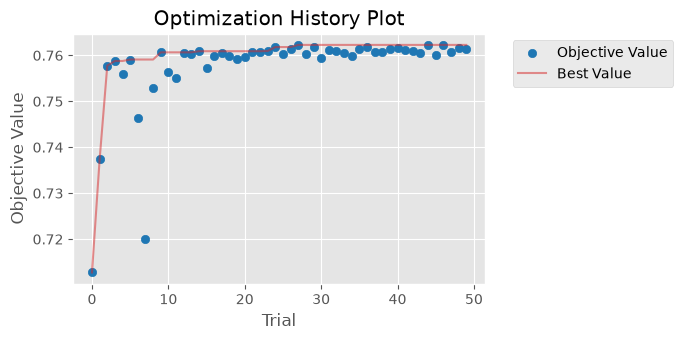

LightGBM tuned: 0.7670 ± 0.0011 (145 с)


In [15]:
fig = optuna.visualization.matplotlib.plot_optimization_history(study)
plt.gcf().set_size_inches(7, 3.5); plt.tight_layout(); plt.savefig('figures/optuna.png'); plt.show()

t0 = time.time()
s = cross_val_score(lgb.LGBMClassifier(**best_params), X_train_fe, y_train, cv=cv, scoring='roc_auc')
log_experiment('lightgbm', 'final_features', best_params, s, note='tuned, full train cv5')
R['cv']['lgb_tuned'] = (float(s.mean()), float(s.std()))
print(f'LightGBM tuned: {s.mean():.4f} ± {s.std():.4f} ({time.time() - t0:.0f} с)')

In [16]:
# CatBoost: число итераций — ранней остановкой на валидационной части обучающей выборки
X_cb = F.to_catboost(X_train_fe)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_cb, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
cb = CatBoostClassifier(iterations=3000, learning_rate=0.05, eval_metric='AUC',
                        early_stopping_rounds=200, random_seed=RANDOM_STATE,
                        verbose=500, thread_count=-1)
t0 = time.time()
cb.fit(X_tr, y_tr, cat_features=cat_cols, eval_set=(X_val, y_val))
CB_PARAMS = dict(iterations=max(cb.get_best_iteration() + 1, 100), learning_rate=0.05,
                 random_seed=RANDOM_STATE, verbose=0, thread_count=-1)
R['cb'] = dict(best_iter=int(cb.get_best_iteration()), val_auc=float(cb.get_best_score()['validation']['AUC']),
               minutes=(time.time() - t0) / 60)
print(R['cb'])

t0 = time.time()
s = []                                     # ручной цикл: CatBoost с cat_features не клонируется sklearn
for tr_i, va_i in cv.split(X_cb, y_train):
    m = CatBoostClassifier(**CB_PARAMS).fit(X_cb.iloc[tr_i], y_train.iloc[tr_i], cat_features=cat_cols)
    s.append(roc_auc_score(y_train.iloc[va_i], m.predict_proba(X_cb.iloc[va_i])[:, 1]))
s = np.array(s)
log_experiment('catboost', 'final_features', CB_PARAMS, s, note='early stopping, cv5')
R['cv']['catboost'] = (float(s.mean()), float(s.std()))
print(f'CatBoost: {s.mean():.4f} ± {s.std():.4f} ({time.time() - t0:.0f} с)')

0:	test: 0.6452392	best: 0.6452392 (0)	total: 248ms	remaining: 12m 24s


500:	test: 0.7632358	best: 0.7632358 (500)	total: 2m 7s	remaining: 10m 35s


1000:	test: 0.7668218	best: 0.7668299 (999)	total: 4m 20s	remaining: 8m 39s


1500:	test: 0.7679307	best: 0.7679307 (1500)	total: 6m 30s	remaining: 6m 29s


2000:	test: 0.7685679	best: 0.7685982 (1985)	total: 8m 42s	remaining: 4m 21s


Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.7686603205
bestIteration = 2039

Shrink model to first 2040 iterations.


{'best_iter': 2039, 'val_auc': 0.7686603204523195, 'minutes': 9.866224253177643}


CatBoost: 0.7671 ± 0.0016 (2307 с)


## Шаг 6. Итоговая оценка на тестовой выборке (один раз)

In [17]:
logreg = baselines['logreg'].fit(X_train, y_train)
p_logreg = logreg.predict_proba(X_test)[:, 1]
cb_final = CatBoostClassifier(**CB_PARAMS).fit(X_cb, y_train, cat_features=cat_cols)
p_cb = cb_final.predict_proba(F.to_catboost(X_test_fe))[:, 1]
final_model = lgb.LGBMClassifier(**best_params).fit(X_train_fe, y_train)
p_lgb = final_model.predict_proba(X_test_fe)[:, 1]

def bootstrap_diff(y_true, score_a, score_b, metric, n_boot=1000):
    # интервалы метрики модели A и разности A − B на одних бутстреп-выборках
    rng = np.random.default_rng(RANDOM_STATE)
    y_true = np.asarray(y_true)
    score_a, score_b = np.asarray(score_a), np.asarray(score_b)
    a_vals, diffs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        a = metric(y_true[idx], score_a[idx])
        a_vals.append(a)
        diffs.append(a - metric(y_true[idx], score_b[idx]))
    return (np.percentile(a_vals, [2.5, 97.5]), np.percentile(diffs, [2.5, 97.5]))

R['test'] = {}
for name, p in [('logreg', p_logreg), ('catboost', p_cb), ('lgb_tuned', p_lgb)]:
    ci, _ = bootstrap_diff(y_test, p, p_logreg, roc_auc_score)
    R['test'][name] = dict(roc_auc=roc_auc_score(y_test, p), pr_auc=average_precision_score(y_test, p),
                           ci=ci.tolist())
ci_m, ci_d_lr = bootstrap_diff(y_test, p_lgb, p_logreg, roc_auc_score)
_, ci_d_cb = bootstrap_diff(y_test, p_lgb, p_cb, roc_auc_score)
R['diff_lgb_logreg'], R['diff_lgb_cb'] = ci_d_lr.tolist(), ci_d_cb.tolist()
print(pd.DataFrame(R['test']).T)
print('LightGBM − logreg:', ci_d_lr.round(4), '| LightGBM − CatBoost:', ci_d_cb.round(4))

            roc_auc    pr_auc                    ci
logreg     0.748669  0.230712  [0.742034, 0.756067]
catboost    0.77134  0.260019  [0.764615, 0.778185]
lgb_tuned   0.77062   0.26287  [0.763844, 0.777352]
LightGBM − logreg: [0.0188 0.0249] | LightGBM − CatBoost: [-0.0023  0.0009]


## Шаг 7. Калибровка и порог

{'raw': 0.06692536148178546, 'isotonic': 0.06694806971131201, 'sigmoid': 0.06690777226495342, 'const': 0.07421079663022367} ROC-AUC после калибровки 0.7697


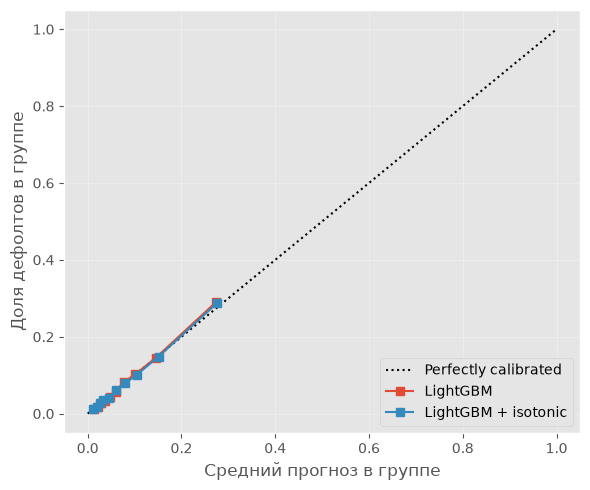

In [18]:
calibrated = CalibratedClassifierCV(lgb.LGBMClassifier(**best_params), method='isotonic', cv=3)
calibrated.fit(X_train_fe, y_train)
p_cal = calibrated.predict_proba(X_test_fe)[:, 1]
sigm = CalibratedClassifierCV(lgb.LGBMClassifier(**best_params), method='sigmoid', cv=3)
p_sig = sigm.fit(X_train_fe, y_train).predict_proba(X_test_fe)[:, 1]
R['brier'] = dict(raw=brier_score_loss(y_test, p_lgb), isotonic=brier_score_loss(y_test, p_cal),
                  sigmoid=brier_score_loss(y_test, p_sig), const=brier_score_loss(y_test, np.full(len(y_test), y_train.mean())))
R['auc_cal'] = roc_auc_score(y_test, p_cal)
R['mean_proba'] = dict(raw=float(p_lgb.mean()), isotonic=float(p_cal.mean()), true=float(y_test.mean()))
print(R['brier'], 'ROC-AUC после калибровки', round(R['auc_cal'], 4))

fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, p_lgb, n_bins=10, strategy='quantile', name='LightGBM', ax=ax)
CalibrationDisplay.from_predictions(y_test, p_cal, n_bins=10, strategy='quantile', name='LightGBM + isotonic', ax=ax)
ax.set(xlabel='Средний прогноз в группе', ylabel='Доля дефолтов в группе'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figures/calibration.png'); plt.show()

In [19]:
def total_cost(y_true, proba, t, c_fn=C_FN, c_fp=C_FP):
    y_true, pred = np.asarray(y_true), np.asarray(proba) >= t
    fn = np.sum(~pred & (y_true == 1))
    fp = np.sum(pred & (y_true == 0))
    return c_fn * fn + c_fp * fp

# out-of-fold прогнозы откалиброванной модели на обучающей выборке
t0 = time.time()
proba_oof = cross_val_predict(
    CalibratedClassifierCV(lgb.LGBMClassifier(**best_params), method='isotonic', cv=3),
    X_train_fe, y_train, cv=cv, method='predict_proba')[:, 1]
grid = np.round(np.arange(0.01, 0.99, 0.01), 2)
costs_oof = np.array([total_cost(y_train, proba_oof, t) for t in grid])
t_best = float(grid[int(np.argmin(costs_oof))])
R.update(t_best=t_best, t_theory=T_THEORY, oof_auc=roc_auc_score(y_train, proba_oof),
         oof_minutes=(time.time() - t0) / 60)
print(f'порог по данным: {t_best:.2f}, теоретический: {T_THEORY:.3f} ({R["oof_minutes"]:.1f} мин)')

порог по данным: 0.13, теоретический: 0.130 (6.1 мин)


                           strategy   TP    FP   FN    TN  precision  recall  reject_share  cost_mln
Одобрять всех (никого не отклонять)    0     0 4965 56538        NaN   0.000         0.000   496.500
                         Порог 0,50  116    73 4849 56465      0.614   0.023         0.003   485.995
          Порог 0,13 (по стоимости) 2598  9028 2367 47510      0.223   0.523         0.189   372.120
                     Отклонять всех 4965 56538    0     0      0.081   1.000         1.000   848.070


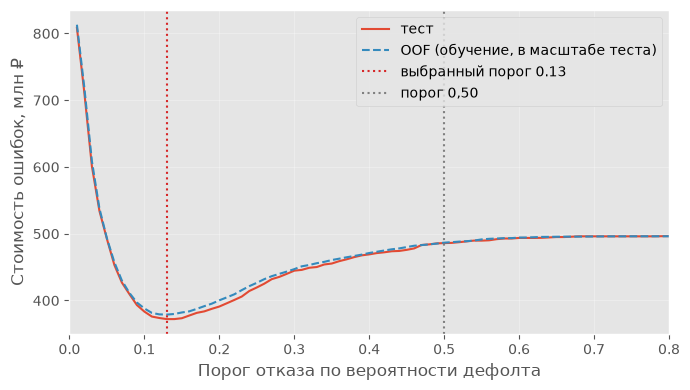

In [20]:
def strategy_row(name, t, p=p_cal):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return dict(strategy=name, TP=tp, FP=fp, FN=fn, TN=tn,
                precision=tp / (tp + fp) if tp + fp else np.nan, recall=tp / (tp + fn),
                reject_share=pred.mean(), cost_mln=(C_FN * fn + C_FP * fp) / 1e6)

strat = pd.DataFrame([strategy_row('Одобрять всех (никого не отклонять)', 1.01),
                      strategy_row('Порог 0,50', 0.5),
                      strategy_row(f'Порог {t_best:.2f} (по стоимости)'.replace('.', ','), t_best),
                      strategy_row('Отклонять всех', 0.0)])
print(strat.round(3).to_string(index=False))
R['strategies'] = strat.to_dict('records')

costs_test = np.array([total_cost(y_test, p_cal, t) for t in grid]) / 1e6
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, costs_test, label='тест')
ax.plot(grid, costs_oof / 1e6 * len(y_test) / len(y_train), '--', label='OOF (обучение, в масштабе теста)')
ax.axvline(t_best, color='tab:red', ls=':', label=f'выбранный порог {t_best:.2f}')
ax.axvline(0.5, color='grey', ls=':', label='порог 0,50')
ax.set(xlabel='Порог отказа по вероятности дефолта', ylabel='Стоимость ошибок, млн ₽', xlim=(0, 0.8))
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('figures/cost_threshold.png'); plt.show()
R['t_best_test'] = float(grid[int(np.argmin(costs_test))])

## Шаг 8. Интерпретация (SHAP)

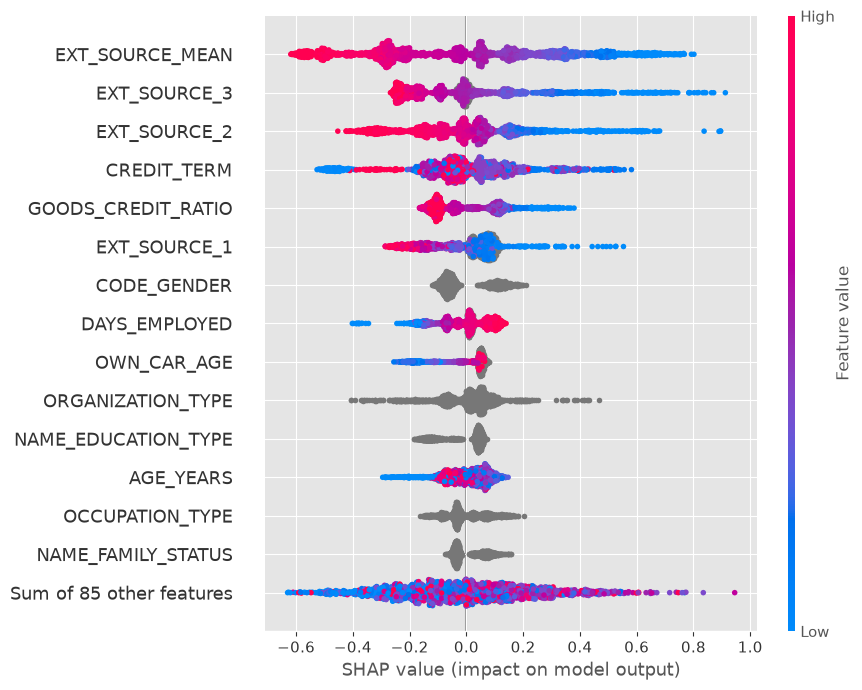

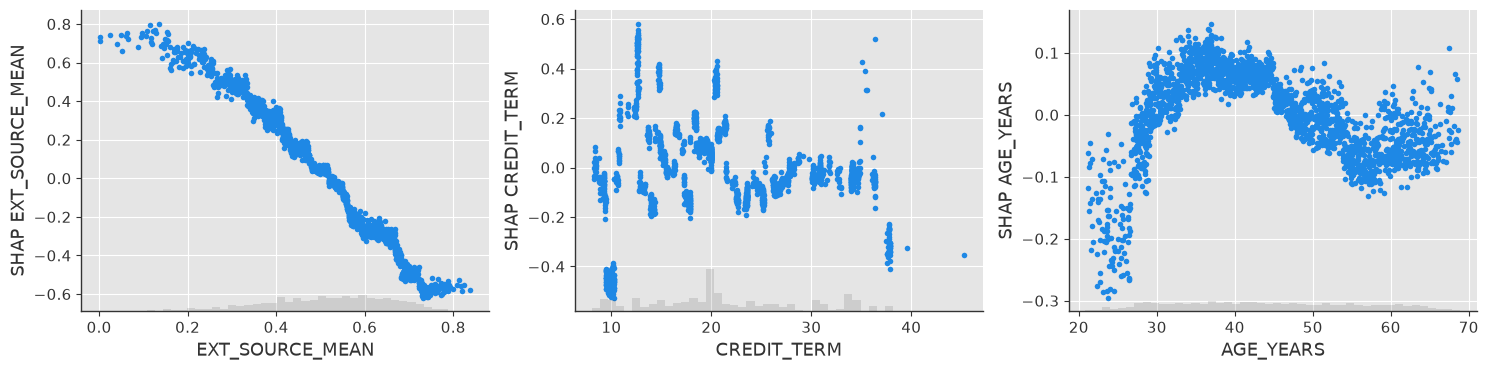

In [21]:
def shap_explanation(model, Xs):
    # точный TreeSHAP средствами LightGBM (pred_contrib), вклады в логитах
    contrib = model.predict(Xs, pred_contrib=True)
    data = Xs.copy()
    for c in cat_cols:                        # у категорий цвет не несёт смысла
        data[c] = np.nan
    return shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1],
                            data=data.astype(float).values, display_data=Xs.astype(object).values,
                            feature_names=list(Xs.columns))

X_expl = X_test_fe.sample(min(2000, len(X_test_fe)), random_state=RANDOM_STATE)
sv = shap_explanation(final_model, X_expl)
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.gcf().set_size_inches(9, 7); plt.tight_layout(); plt.savefig('figures/shap_beeswarm.png'); plt.show()

KEY = ['EXT_SOURCE_MEAN', 'CREDIT_TERM', 'AGE_YEARS']
KEY = [k for k in KEY if k in X_expl.columns]
fig, axes = plt.subplots(1, len(KEY), figsize=(5 * len(KEY), 3.8))
for ax, k in zip(np.atleast_1d(axes), KEY):
    shap.plots.scatter(sv[:, k], ax=ax, show=False)
    ax.set_ylabel(f'SHAP {k}')
plt.tight_layout(); plt.savefig('figures/shap_scatter.png'); plt.show()

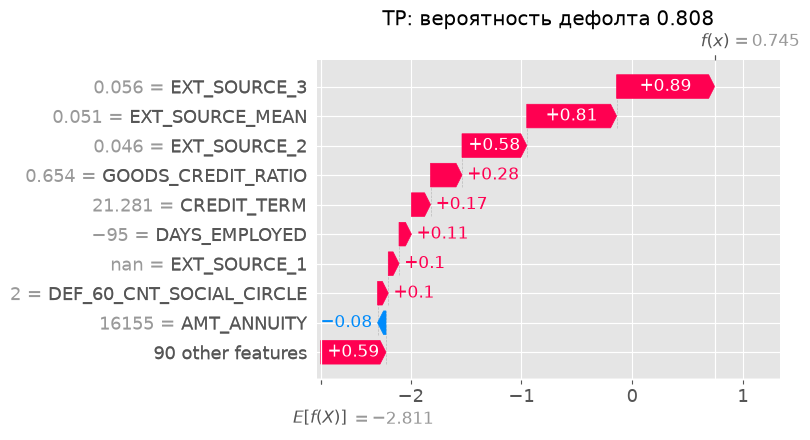

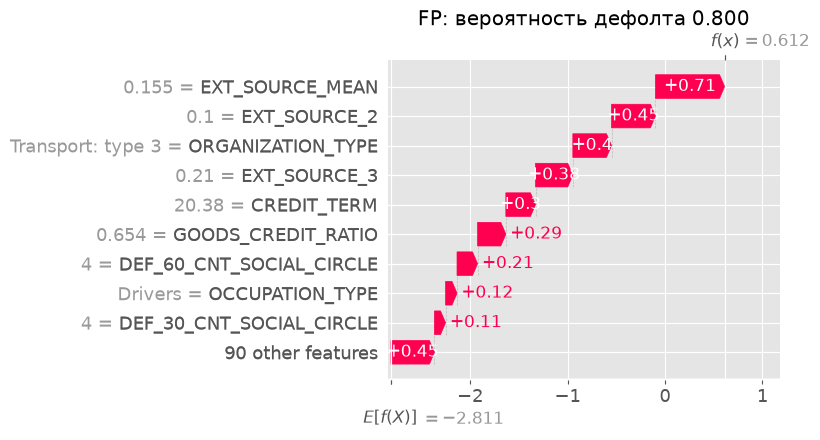

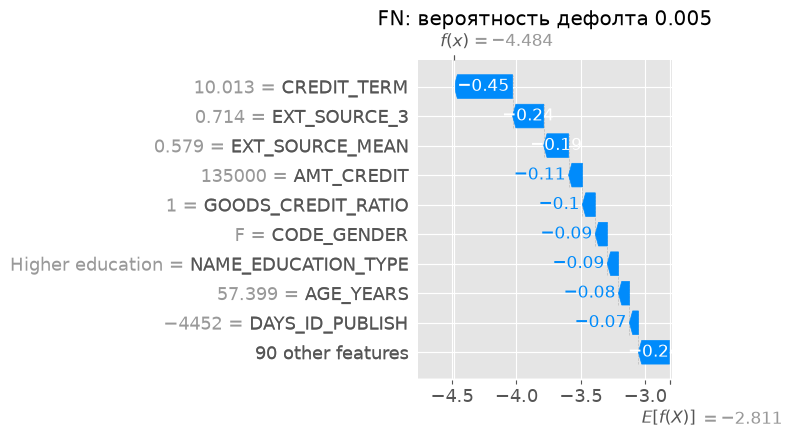

{
 "TP": {
  "proba": 0.8079157588961511,
  "top": {
   "EXT_SOURCE_3": 0.8850944333175164,
   "EXT_SOURCE_MEAN": 0.810963181255286,
   "EXT_SOURCE_2": 0.5844757346668021,
   "GOODS_CREDIT_RATIO": 0.2842170349715091
  },
  "vals": {
   "EXT_SOURCE_3": "0.056092078848294",
   "EXT_SOURCE_MEAN": "0.051031693942717754",
   "EXT_SOURCE_2": "0.0459713090371415",
   "GOODS_CREDIT_RATIO": "0.6544502617801047"
  }
 },
 "FP": {
  "proba": 0.7996201329534663,
  "top": {
   "EXT_SOURCE_MEAN": 0.7095265764655454,
   "EXT_SOURCE_2": 0.45068941546969493,
   "ORGANIZATION_TYPE": 0.3969864732187733,
   "EXT_SOURCE_3": 0.3830785967027782
  },
  "vals": {
   "EXT_SOURCE_MEAN": "0.15539396456387788",
   "EXT_SOURCE_2": "0.1004377004333064",
   "ORGANIZATION_TYPE": "Transport: type 3",
   "EXT_SOURCE_3": "0.2103502286944494"
  }
 },
 "FN": {
  "proba": 0.004967418119968473,
  "top": {
   "CREDIT_TERM": -0.45424386934946265,
   "EXT_SOURCE_3": -0.24168881395926206,
   "EXT_SOURCE_MEAN": -0.1932503931169968

In [22]:
pred_t = p_cal >= t_best
yt = y_test.values
cases = {
    'TP': np.where(pred_t & (yt == 1))[0][np.argmax(p_cal[pred_t & (yt == 1)])],
    'FP': np.where(pred_t & (yt == 0))[0][np.argmax(p_cal[pred_t & (yt == 0)])],
    'FN': np.where(~pred_t & (yt == 1))[0][np.argmin(p_cal[~pred_t & (yt == 1)])],
}
R['cases'] = {}
for k, i in cases.items():
    e = shap_explanation(final_model, X_test_fe.iloc[[i]])
    shap.plots.waterfall(e[0], max_display=10, show=False)
    plt.gcf().set_size_inches(8, 4.5); plt.title(f'{k}: вероятность дефолта {p_cal[i]:.3f}')
    plt.tight_layout(); plt.savefig(f'figures/shap_waterfall_{k}.png'); plt.show()
    top = pd.Series(e.values[0], index=e.feature_names).sort_values(key=abs, ascending=False).head(4)
    R['cases'][k] = dict(proba=float(p_cal[i]), top={f: float(v) for f, v in top.items()},
                         vals={f: str(X_test_fe.iloc[i][f]) for f in top.index})
print(json.dumps(R['cases'], ensure_ascii=False, indent=1))

In [23]:
imp = pd.DataFrame({'mean_abs_shap': np.abs(sv.values).mean(axis=0),
                    'gain': final_model.booster_.feature_importance('gain')},
                   index=sv.feature_names)
imp['rank_shap'] = imp['mean_abs_shap'].rank(ascending=False).astype(int)
imp['rank_gain'] = imp['gain'].rank(ascending=False).astype(int)
imp = imp.sort_values('rank_shap')
print(imp.head(12).round(3))
R['importance'] = imp.head(10).reset_index().rename(columns={'index': 'feature'}).to_dict('records')
from scipy.stats import spearmanr
R['rank_corr'] = float(spearmanr(imp['mean_abs_shap'], imp['gain']).correlation)
print('Корреляция Спирмена рангов SHAP и gain:', round(R['rank_corr'], 3))

                     mean_abs_shap        gain  rank_shap  rank_gain
EXT_SOURCE_MEAN              0.288  181742.798          1          1
EXT_SOURCE_3                 0.170   92069.658          2          3
EXT_SOURCE_2                 0.145  123898.476          3          2
CREDIT_TERM                  0.129   72271.055          4          4
GOODS_CREDIT_RATIO           0.107   29505.764          5          8
EXT_SOURCE_1                 0.094   36037.508          6          5
CODE_GENDER                  0.081    7992.473          7         15
DAYS_EMPLOYED                0.071   16563.040          8         12
OWN_CAR_AGE                  0.070   12871.272          9         13
ORGANIZATION_TYPE            0.069   30625.547         10          7
NAME_EDUCATION_TYPE          0.063    8291.930         11         14
AGE_YEARS                    0.058   33519.172         12          6
Корреляция Спирмена рангов SHAP и gain: 0.964


## Дополнительное задание: справедливость по полу и возрасту

In [24]:
test_info = pd.DataFrame({'y': yt, 'reject': pred_t, 'gender': X_test['CODE_GENDER'].values,
                          'age': pd.cut(-X_test['DAYS_BIRTH'].values / 365.25, [20, 30, 45, 60, 70],
                                        right=False).astype(str)})
def group_report(col):
    g = test_info.groupby(col)
    return pd.DataFrame({'n': g.size(), 'default_rate': g['y'].mean(), 'reject_share': g['reject'].mean(),
                         'recall': g.apply(lambda d: d.loc[d.y == 1, 'reject'].mean()),
                         'fpr': g.apply(lambda d: d.loc[d.y == 0, 'reject'].mean())})
fair_g = group_report('gender').drop(index='XNA', errors='ignore')
fair_a = group_report('age')
print(fair_g.round(3), '\n', fair_a.round(3))
R['fair_gender'] = fair_g.round(4).reset_index().to_dict('records')
R['fair_age'] = fair_a.round(4).reset_index().to_dict('records')

# модель без признака пола
X_tr_ng, X_te_ng = X_train_fe.drop(columns='CODE_GENDER'), X_test_fe.drop(columns='CODE_GENDER')
cal_ng = CalibratedClassifierCV(lgb.LGBMClassifier(**best_params), method='isotonic', cv=3).fit(X_tr_ng, y_train)
p_ng = cal_ng.predict_proba(X_te_ng)[:, 1]
rej_ng = p_ng >= t_best
R['no_gender'] = dict(auc=roc_auc_score(y_test, p_ng), cost_mln=total_cost(y_test, p_ng, t_best) / 1e6,
                      reject_F=float(rej_ng[test_info.gender == 'F'].mean()),
                      reject_M=float(rej_ng[test_info.gender == 'M'].mean()),
                      recall_F=float(rej_ng[(test_info.gender == 'F') & (yt == 1)].mean()),
                      recall_M=float(rej_ng[(test_info.gender == 'M') & (yt == 1)].mean()),
                      fpr_F=float(rej_ng[(test_info.gender == 'F') & (yt == 0)].mean()),
                      fpr_M=float(rej_ng[(test_info.gender == 'M') & (yt == 0)].mean()))
print(R['no_gender'])

            n  default_rate  reject_share  recall    fpr
gender                                                  
F       40561         0.070         0.149   0.451  0.126
M       20940         0.102         0.267   0.619  0.227 
               n  default_rate  reject_share  recall    fpr
age                                                       
[20, 30)   8905         0.113         0.344   0.667  0.303
[30, 45)  24744         0.088         0.217   0.571  0.183
[45, 60)  20663         0.069         0.134   0.428  0.113
[60, 70)   7191         0.050         0.057   0.202  0.049


{'auc': 0.7692379537301633, 'cost_mln': np.float64(371.92), 'reject_F': 0.15704741007371614, 'reject_M': 0.2444603629417383, 'recall_F': 0.4665021156558533, 'recall_M': 0.5913574448097698, 'fpr_F': 0.13378396288933067, 'fpr_M': 0.20519908564138004}


## Шаг 9. Сохранение модели

In [25]:
import joblib
final_pipeline = Pipeline([
    ('prepare', FunctionTransformer(F.prepare)),
    ('select', FunctionTransformer(F.drop_columns, kw_args={'cols': REMOVED})),
    ('model', CalibratedClassifierCV(lgb.LGBMClassifier(**best_params), method='isotonic', cv=3)),
])
final_pipeline.fit(X_train, y_train)
joblib.dump({'pipeline': final_pipeline, 'threshold': t_best, 'c_fn': C_FN, 'c_fp': C_FP,
             'positive_class': 'TARGET=1 (дефолт) → отказ', 'sklearn': sklearn.__version__,
             'lightgbm': lgb.__version__}, 'model.joblib')
assert np.allclose(final_pipeline.predict_proba(X_test)[:, 1], p_cal)

def column_schema(s):
    if pd.api.types.is_numeric_dtype(s):
        return {'type': 'number', 'min': float(s.min()), 'max': float(s.max()),
                'nullable': bool(s.isna().any())}
    return {'type': 'category', 'values': sorted(s.dropna().astype(str).unique().tolist()),
            'nullable': bool(s.isna().any())}

schema = {col: column_schema(X_train[col]) for col in X_train.columns if col != F.ID_COL}
with open('input_schema.json', 'w', encoding='utf-8') as f:
    json.dump(schema, f, ensure_ascii=False, indent=2)

# проверка загрузки в отдельном процессе
X_test.head(20).to_csv('figures/_check.csv', index=False)
check = subprocess.run([sys.executable, '-c',
    "import joblib, pandas as pd, numpy as np; b = joblib.load('model.joblib'); "
    "X = pd.read_csv('figures/_check.csv'); print(','.join(str(float(v)) for v in b['pipeline'].predict_proba(X)[:, 1]))"],
    capture_output=True, text=True, check=True)
p_loaded = np.array([float(v) for v in check.stdout.strip().split(',')])
assert np.allclose(p_loaded, p_cal[:20])
os.remove('figures/_check.csv')
R.update(model_mb=os.path.getsize('model.joblib') / 2**20, n_schema=len(schema),
         n_experiments=len(pd.read_csv(EXP_LOG)))
print('Проверка загрузки пройдена; model.joblib', round(R['model_mb'], 1), 'МБ;',
      'признаков на входе', len(schema), '; записей в журнале', R['n_experiments'])

Проверка загрузки пройдена; model.joblib 8.2 МБ; признаков на входе 120 ; записей в журнале 69


In [26]:
def to_jsonable(o):
    if isinstance(o, dict): return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
with open('results.json', 'w', encoding='utf-8') as f:
    json.dump(to_jsonable(R), f, ensure_ascii=False, indent=1)
print('results.json сохранён')

results.json сохранён
